# Most In-Demand Skills for Leading Data Roles

This analysis compares the skills requested for the three most common data roles in U.S. job postings. Both raw demand and the percentage of postings that mention each skill are examined so that roles with different numbers of openings can be compared fairly.

## Analysis approach

1. Prepare the job-postings dataset and focus on the United States.
2. Expand each posting's skills into individual rows.
3. Count skill mentions for each role and identify the leading roles.
4. Convert counts to percentages using the total postings for each role.
5. Visualize the five most frequently requested skills by both measures.

## Load and prepare the data

Import the required libraries, load the job-postings dataset, and convert the posting date and skills columns into analysis-ready formats.

In [1]:
# Importing Libraries
import ast

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

# Loading Data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

# Data Cleanup
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

d:\Data_Analyst\Resources\Code\Python\Python_Data_Analytics_Course\Playground\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Focus on the U.S. market

Restrict the dataset to job postings located in the United States and set a consistent chart theme for the remaining analysis.

In [2]:
# Only get data analyst jobs
df_US = df[df["job_country"] == "United States"].copy()

# Set Theme
sns.set_theme(style="ticks", font_scale=1.2)

## Expand the skills field

Each posting can list several skills. Exploding `job_skills` creates one row per posting-skill combination, making individual skill mentions countable.

In [3]:
df_skills = df_US.explode("job_skills")
df_skills[["job_title", "job_skills"]]

,job_title,job_skills
0,Senior Clinical Data Engineer / Principal Clin...,NaN
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,python
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,c++
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,java
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,matlab
...,...,...
785692,Data Scientist- Hybrid Work Location,r
785703,Data Analyst - CRYPTOGRAPHY - Full-time,NaN
785705,Expert Business Data Analyst - Now Hiring,sql
785705,Expert Business Data Analyst - Now Hiring,python


## Count skills within each role

Group the expanded data by skill and standardized job title, then count and rank the resulting combinations by the number of mentions.

In [7]:
df_skill_count = df_skills.groupby(["job_skills", "job_title_short"]).size()
df_skill_count = df_skill_count.reset_index(name="skill_count")
df_skill_count.sort_values(by="skill_count", ascending=False, inplace=True)

df_skill_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


## Select the three leading roles

Build a sorted list of the three job-title categories associated with the highest-ranked skill counts. These roles define the comparison shown below.

In [8]:
job_titles = df_skill_count["job_title_short"].unique().tolist()
job_titles = sorted(job_titles[:3])

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

## Compare skills by number of postings

Plot the five skills with the largest number of mentions for each selected role. Raw counts show the overall volume of demand, but they are influenced by how many postings exist for each role.

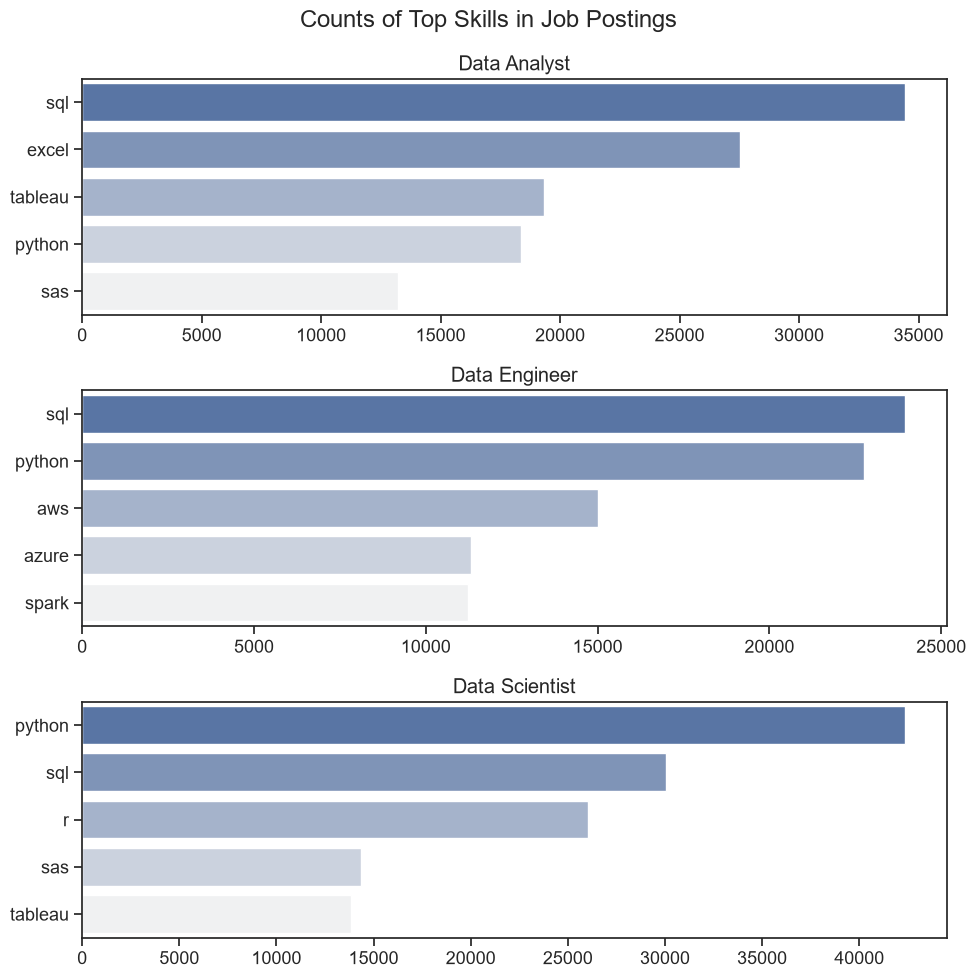

In [32]:
fig, ax = plt.subplots(len(job_titles), 1, figsize=(10, 10))

for idx, job_title in enumerate(job_titles):
	df_plot = df_skill_count[df_skill_count["job_title_short"] == job_title].nlargest(
		5, "skill_count"
	)

	sns.barplot(
		data=df_plot,
		x="skill_count",
		y="job_skills",
		hue="job_skills",
		palette="light:b_r",
		legend=False,
		ax=ax[idx],
	)

	ax[idx].set_title(job_title)
	ax[idx].set_ylabel("")
	ax[idx].set_xlabel("")

fig.suptitle("Counts of Top Skills in Job Postings")

plt.tight_layout()
plt.show()

## Establish the role-level denominators

Count all U.S. postings in each standardized job-title category. These totals provide the denominator needed to measure how prevalent a skill is within a role.

In [14]:
df_job_title_count = df_US["job_title_short"].value_counts().reset_index(name="jobs_total")

df_job_title_count

,job_title_short,jobs_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


## Calculate skill prevalence

Join each skill count to its role's total number of postings, then calculate the percentage of postings that request the skill.

In [19]:
df_skills_perc = pd.merge(df_skill_count, df_job_title_count, how="left", on="job_title_short")
df_skills_perc["skill_percent"] = 100 * df_skills_perc["skill_count"] / df_skills_perc["jobs_total"]

df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


## Compare skills by share of postings

Display the five skills with the highest prevalence in each role. Percentages reveal how consistently employers request a skill while controlling for differences in job-posting volume.

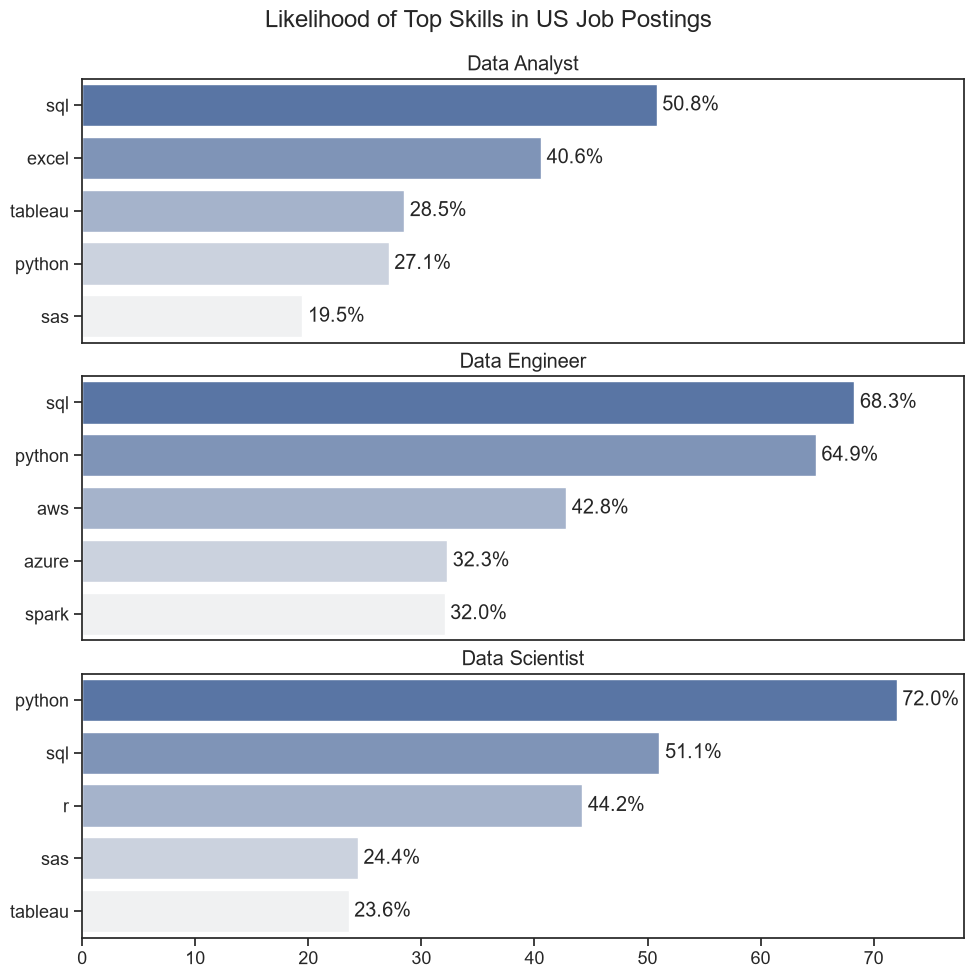

In [50]:
fig, ax = plt.subplots(len(job_titles), 1, figsize=(10, 10))

for idx, job_title in enumerate(job_titles):
	df_plot = df_skills_perc[df_skills_perc["job_title_short"] == job_title].nlargest(
		5, "skill_percent"
	)

	sns.barplot(
		data=df_plot,
		x="skill_percent",
		y="job_skills",
		hue="job_skills",
		palette="light:b_r",
		legend=False,
		ax=ax[idx],
	)

	ax[idx].set_title(job_title)
	ax[idx].set_ylabel("")
	ax[idx].set_xlabel("")
	ax[idx].set_xlim(0, 78)

	for i, value in enumerate(df_plot["skill_percent"]):
		ax[idx].text(value + 0.5, i, f"{value:.1f}%", va="center")

	if idx != len(job_titles) - 1:
		ax[idx].set_xticks([])

fig.suptitle("Likelihood of Top Skills in US Job Postings")

plt.tight_layout(h_pad=0.5)
plt.show()